# Titanic: разведочный анализ данных

## Основные выводы

- В обучающей выборке 891 строка; доля выживших составляет около 38%, поэтому для валидации используется Stratified K-fold.
- Самые сильные наблюдаемые связи с таргетом дают пол и класс билета: женщины и пассажиры более высокого класса выживали заметно чаще. Порт посадки также связан с таргетом, но частично отражает различия в классе билета.
- В Age отсутствует около 20% значений, в Cabin — около 77%, в Embarked — менее 1%. Для числовых признаков выбрана медианная импутация с индикатором пропуска, для категориальных — наиболее частое значение.
- Fare имеет выраженный правый хвост и выбросы. Деревья и бустинги устойчивы к ним; для линейных моделей, KNN и DNN числовые признаки стандартизируются.
- Полных дубликатов и константных признаков не обнаружено. Сильной линейной корреляции между исходными числовыми признаками нет.
- FamilySize, IsAlone, Title и CabinDeck были проверены отдельно, но не улучшили 5-fold CV финального Random Forest, поэтому финальный ансамбль использует исходные семь признаков.

In [53]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

In [54]:
df = pd.read_csv('titanic/train.csv').copy()
print(df.head(5).to_string(index=False))

 PassengerId  Survived  Pclass                                                Name    Sex  Age  SibSp  Parch           Ticket    Fare Cabin Embarked
           1         0       3                             Braund, Mr. Owen Harris   male 22.0      1      0        A/5 21171  7.2500   NaN        S
           2         1       1 Cumings, Mrs. John Bradley (Florence Briggs Thayer) female 38.0      1      0         PC 17599 71.2833   C85        C
           3         1       3                              Heikkinen, Miss. Laina female 26.0      0      0 STON/O2. 3101282  7.9250   NaN        S
           4         1       1        Futrelle, Mrs. Jacques Heath (Lily May Peel) female 35.0      1      0           113803 53.1000  C123        S
           5         0       3                            Allen, Mr. William Henry   male 35.0      0      0           373450  8.0500   NaN        S


In [55]:
print('Размеры:', df.shape)
print('Столбцы:', df.columns.tolist())

Размеры: (891, 12)
Столбцы: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


Survived
0    549
1    342
Name: count, dtype: int64

Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64

<Axes: xlabel='Survived', ylabel='count'>

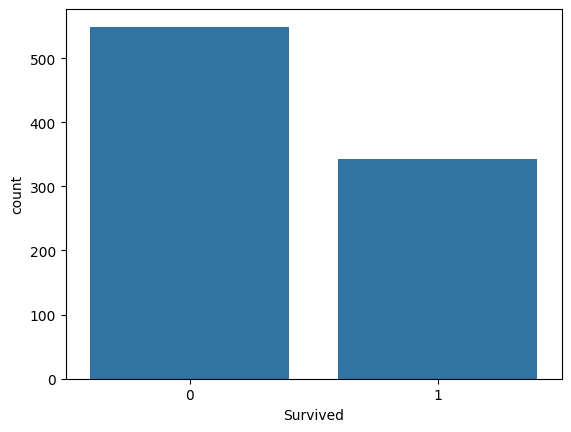

In [56]:
target = 'Survived'
display(df[target].value_counts())
display(df[target].value_counts(normalize=True))
sns.countplot(data=df, x = target)


In [57]:
summary = pd.DataFrame({
    'dtypes': df.dtypes,
    'unique' :df.nunique(),
    'missing': df.isnull().sum(),
    '%missing': df.isnull().mean()*100   
})
display(summary)

,dtypes,unique,missing,%missing
PassengerId,int64,891,0,0.000000
Survived,int64,2,0,0.000000
Pclass,int64,3,0,0.000000
Name,object,891,0,0.000000
Sex,object,2,0,0.000000
Age,float64,88,177,19.865320
SibSp,int64,7,0,0.000000
Parch,int64,7,0,0.000000
Ticket,object,681,0,0.000000
Fare,float64,248,0,0.000000


In [58]:
display("Полных дубликатов:", df.duplicated().sum())

'Полных дубликатов:'

np.int64(0)

In [59]:
display(df.describe().T)
display(df.describe(include='object').T)

,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


,count,unique,top,freq
Name,891,891,"Braund, Mr. Owen Harris",1
Sex,891,2,male,577
Ticket,891,681,347082,7
Cabin,204,147,B96 B98,4
Embarked,889,3,S,644



Признак: Pclass


Survived,0,1
Pclass,,
1,0.370,0.630
2,0.527,0.473
3,0.758,0.242


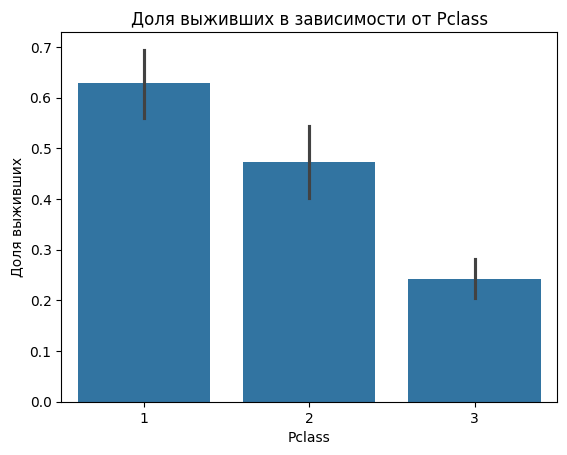


Признак: Sex


Survived,0,1
Sex,,
female,0.258,0.742
male,0.811,0.189


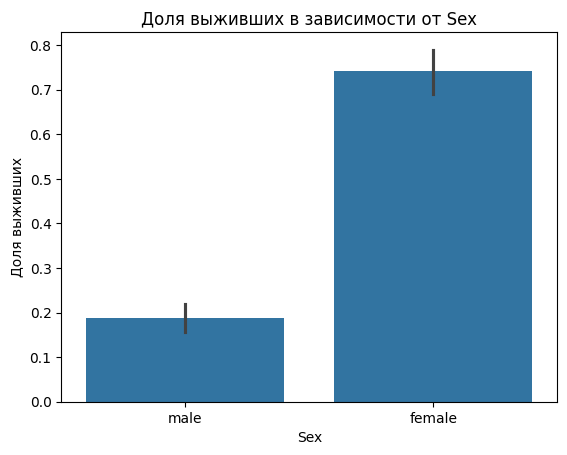


Признак: Embarked


Survived,0,1
Embarked,,
C,0.446,0.554
Q,0.610,0.390
S,0.663,0.337


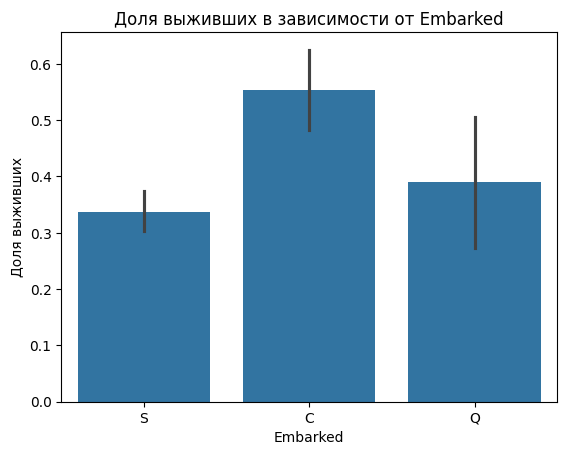

In [60]:
categorical_features = ["Pclass", "Sex", "Embarked"]
for column in categorical_features:
    print(f"\nПризнак: {column}")

    display(
        pd.crosstab(
            df[column],
            df[target],
            normalize="index"
        ).round(3)
    )

    sns.barplot(data=df, x=column, y=target)
    plt.title(f"Доля выживших в зависимости от {column}")
    plt.ylabel("Доля выживших")
    plt.show()

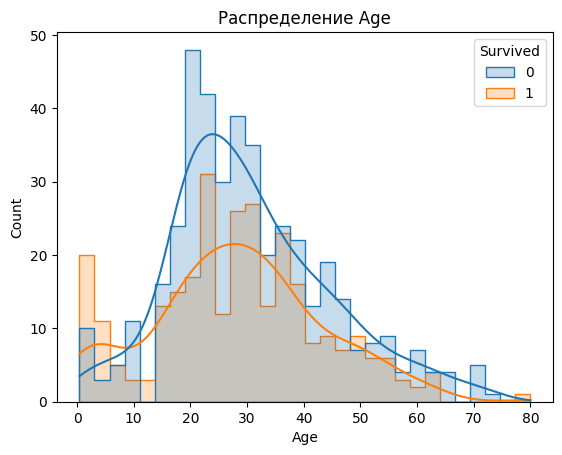

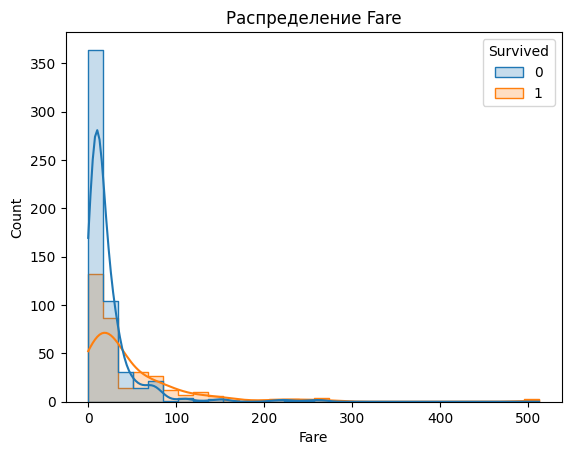

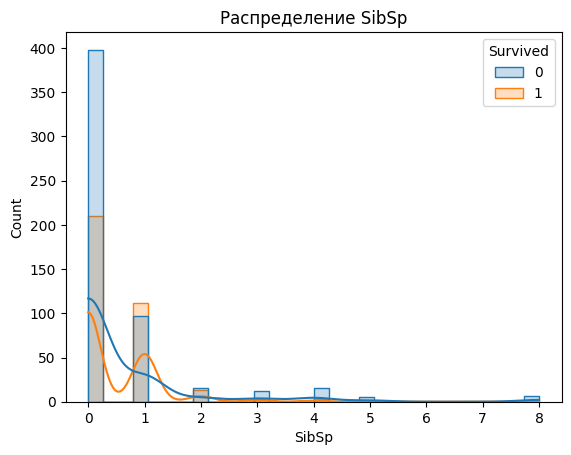

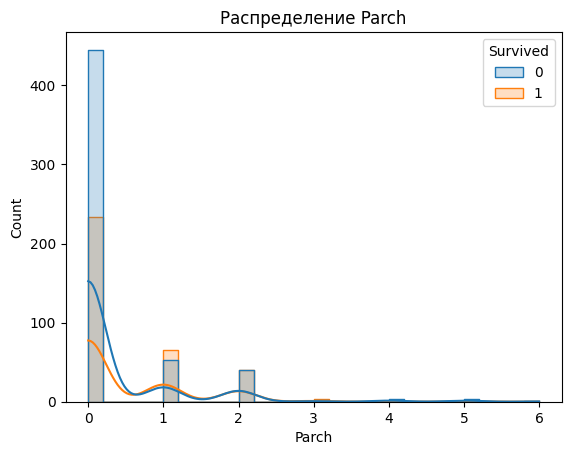

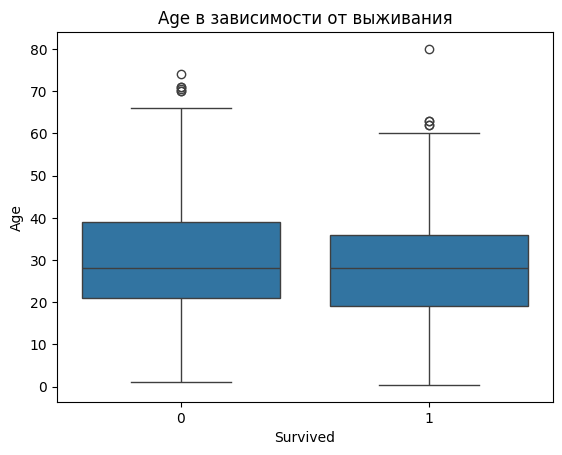

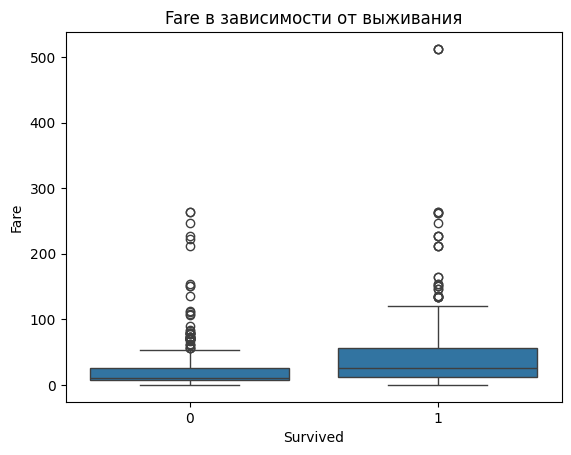

Age          Fare        SibSp        Parch       
           mean median   mean median  mean median  mean median
Survived                                                      
0         30.63   28.0  22.12   10.5  0.55    0.0  0.33    0.0
1         28.34   28.0  48.40   26.0  0.47    0.0  0.46    0.0

In [61]:
numeric_features = ["Age", "Fare", "SibSp", "Parch"]

for column in numeric_features:
    sns.histplot(
        data=df,
        x=column,
        hue=target,
        bins=30,
        kde=True,
        element="step",
    )
    plt.title(f"Распределение {column}")
    plt.show()

for column in ["Age", "Fare"]:
    sns.boxplot(data=df, x=target, y=column)
    plt.title(f"{column} в зависимости от выживания")
    plt.show()

display(
    df.groupby(target)[numeric_features]
      .agg(["mean", "median"])
      .round(2)
)

In [62]:
missing = (
    df.isna()
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)
display("Признаки с пропусками:", missing)
display(missing[missing > 0])

'Признаки с пропусками:'

Cabin          77.104377
Age            19.865320
Embarked        0.224467
PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
dtype: float64

Cabin       77.104377
Age         19.865320
Embarked     0.224467
dtype: float64

In [63]:
numeric_df =  df.select_dtypes(include="number")
display(numeric_df.columns.tolist())

display(numeric_df.corr())

['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
PassengerId,1.000000,-0.005007,-0.035144,0.036847,-0.057527,-0.001652,0.012658
Survived,-0.005007,1.000000,-0.338481,-0.077221,-0.035322,0.081629,0.257307
Pclass,-0.035144,-0.338481,1.000000,-0.369226,0.083081,0.018443,-0.549500
Age,0.036847,-0.077221,-0.369226,1.000000,-0.308247,-0.189119,0.096067
SibSp,-0.057527,-0.035322,0.083081,-0.308247,1.000000,0.414838,0.159651
Parch,-0.001652,0.081629,0.018443,-0.189119,0.414838,1.000000,0.216225
Fare,0.012658,0.257307,-0.549500,0.096067,0.159651,0.216225,1.000000


In [64]:
train_data = pd.read_csv('titanic/train.csv')
test_data = pd.read_csv('titanic/test.csv')

missing_report = pd.DataFrame({
    "train_missing": train_data.isnull().sum(),
    "train_missing_%": train_data.isnull().mean() * 100,
    "test_missing": test_data.isnull().sum(),
    "test_missing_%": test_data.isnull().mean() * 100,
})


missing_report = missing_report[(missing_report["train_missing"] > 0) | (missing_report["test_missing"] > 0)]
display("Признаки с пропусками в train и test:", missing_report)

'Признаки с пропусками в train и test:'

,train_missing,train_missing_%,test_missing,test_missing_%
Age,177,19.865320,86.0,20.574163
Cabin,687,77.104377,327.0,78.229665
Embarked,2,0.224467,0.0,0.000000
Fare,0,0.000000,1.0,0.239234


,Age,SibSp,Parch,Fare,Pclass,Survived
Age,1.00,-0.31,-0.19,0.10,-0.37,-0.08
SibSp,-0.31,1.00,0.41,0.16,0.08,-0.04
Parch,-0.19,0.41,1.00,0.22,0.02,0.08
Fare,0.10,0.16,0.22,1.00,-0.55,0.26
Pclass,-0.37,0.08,0.02,-0.55,1.00,-0.34
Survived,-0.08,-0.04,0.08,0.26,-0.34,1.00


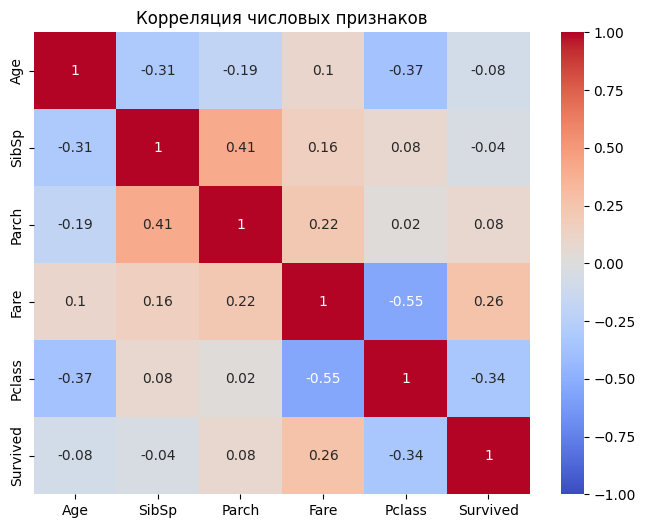

In [65]:
correlation_columns = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Pclass",
    "Survived",
]

correlation_matrix = (
    train_data[correlation_columns]
    .corr()
    .round(2)
)

display(correlation_matrix)

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
)

plt.title("Корреляция числовых признаков")
plt.show()

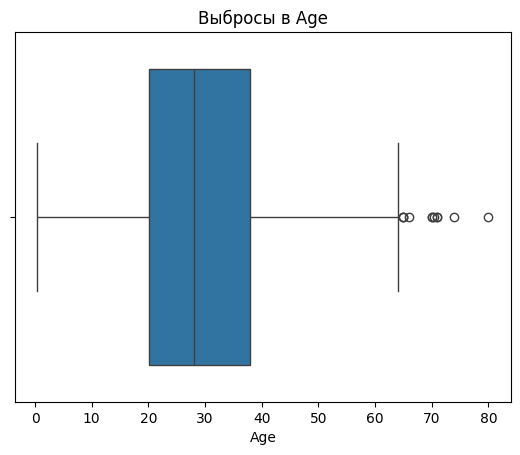

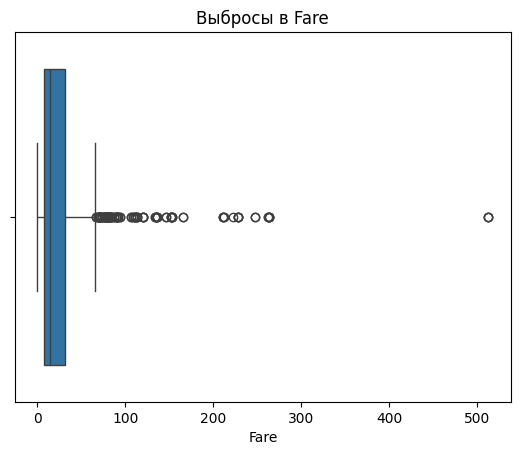

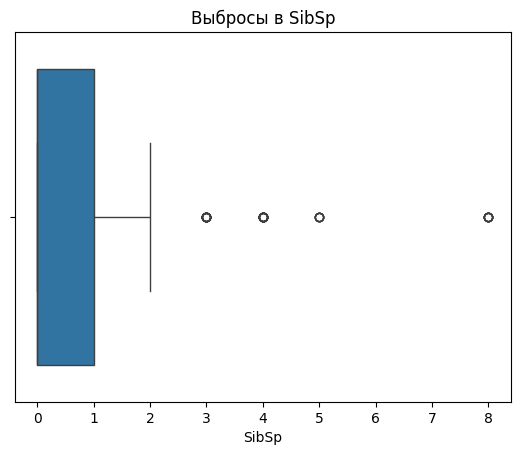

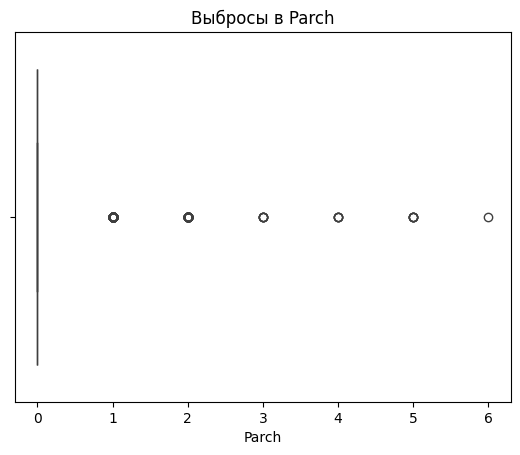

In [66]:
features_for_outliers = [
    "Age",
    "Fare",
    "SibSp",
    "Parch",
]

for feature in features_for_outliers:
    sns.boxplot(
        data=train_data,
        x=feature,
    )

    plt.title(f"Выбросы в {feature}")
    plt.show()

In [67]:
display(
    train_data[features_for_outliers]
    .describe(
    percentiles=[
        0.01,
        0.05,
        0.25,
        0.50,
        0.75,
        0.95,
        0.99,
    ])
    .T
)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Age,714.0,29.699118,14.526497,0.42,1.0,4.000,20.1250,28.0000,38.0,56.00000,65.87000,80.0000
Fare,891.0,32.204208,49.693429,0.00,0.0,7.225,7.9104,14.4542,31.0,112.07915,249.00622,512.3292
SibSp,891.0,0.523008,1.102743,0.00,0.0,0.000,0.0000,0.0000,1.0,3.00000,5.00000,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0,0.000,0.0000,0.0000,0.0,2.00000,4.00000,6.0000
